# 모델 검증 및 평가 — 혼동 행렬 · 정밀도 · 재현율 · F1 · 특성 중요도

수업에서 `accuracy_score` → **`classification_report`** 로 평가 지표를 바꾼 부분과, 교재 `모델검증및평가교재` (18. 모델 검증 및 평가) 를 튜닝한 모델로 실습한 노트입니다.

- 모델 : [`hyperparameter_search_rf_xgb.ipynb`](./hyperparameter_search_rf_xgb.ipynb) 에서 튜닝한 결정 트리 · 랜덤 포레스트 · XGBoost
- 원본에서 고친 부분은 **📝 고친 부분** 으로 따로 적어 두었습니다.

In [1]:
# 그래프 한글 폰트 설정 (운영체제별)
import platform
import matplotlib.pyplot as plt

if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
else:
    plt.rcParams['font.family'] = 'Noto Sans CJK JP'
plt.rcParams['axes.unicode_minus'] = False

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# 데이터 불러오기 (노트북과 같은 폴더)
df = pd.read_csv('./diabetes_binary_5050split_health_indicators_BRFSS2015.csv')

X_data = df.drop(columns=['Diabetes_binary'])   # 특성 21개
y_data = df['Diabetes_binary']                   # 정답 0.0 / 1.0

# 학습용 80% : 평가용 20% — 수업과 같은 분할
X_train, X_test, y_train, y_test = train_test_split(
    X_data, y_data, test_size=0.2, random_state=0, stratify=y_data)
print("학습용 :", X_train.shape, " 평가용 :", X_test.shape)

학습용 : (56553, 21)  평가용 : (14139, 21)


In [3]:
# 튜닝한 모델 3개 — hyperparameter_search_rf_xgb.ipynb 에서 저장한 파일이 있으면 불러오고,
# 없으면 거기서 찾은 최적 조합으로 바로 학습한다 (탐색을 다시 돌리지 않음)
import os, joblib
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

def load_or_fit(name, model):
    path = f'./models/{name}.pkl'
    if os.path.exists(path):
        return joblib.load(path)
    return model.fit(X_train, y_train)

best_dt  = load_or_fit('best_dt',  DecisionTreeClassifier(max_depth=7, min_samples_leaf=5, random_state=0))
best_rf  = load_or_fit('best_rf',  RandomForestClassifier(**{'n_estimators': 400, 'max_depth': 9, 'min_samples_leaf': 2}, random_state=0))
best_xgb = load_or_fit('best_xgb', XGBClassifier(**{'n_estimators': 200, 'learning_rate': 0.05, 'max_depth': 4}, random_state=0))
for m in [best_dt, best_rf, best_xgb]:
    print(type(m).__name__, {k: m.get_params()[k] for k in ['max_depth', 'min_samples_leaf', 'n_estimators', 'learning_rate'] if k in m.get_params()})

DecisionTreeClassifier {'max_depth': 7, 'min_samples_leaf': 5}
RandomForestClassifier {'max_depth': 9, 'min_samples_leaf': 2, 'n_estimators': 400}
XGBClassifier {'max_depth': 4, 'n_estimators': 200, 'learning_rate': 0.05}


## 1. 혼동 행렬 (Confusion matrix)

실제 정답과 모델의 예측을 비교한 **2 × 2 표**. 여기서 **양성(Positive) = 당뇨(1)**.

| | 예측 0 (음성) | 예측 1 (양성) |
|---|---|---|
| **정답 0** | TN (맞게 음성) | **FP** (아닌데 당뇨라고 함) |
| **정답 1** | **FN** (당뇨인데 놓침) | TP (맞게 양성) |

[[5079 1991]
 [1482 5587]]
TN 5,079  FP 1,991  FN 1,482  TP 5,587


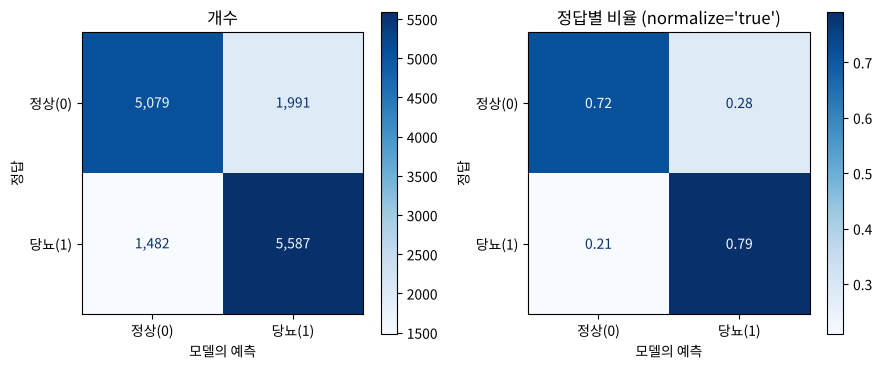

In [4]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

pred = best_xgb.predict(X_test)
cm = confusion_matrix(y_test, pred)          # [[TN, FP], [FN, TP]]
tn, fp, fn, tp = cm.ravel()
print(cm)
print(f"TN {tn:,}  FP {fp:,}  FN {fn:,}  TP {tp:,}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
ConfusionMatrixDisplay(cm, display_labels=['정상(0)', '당뇨(1)']).plot(ax=axes[0], cmap='Blues', values_format=',')
axes[0].set_title('개수'); axes[0].set_xlabel('모델의 예측'); axes[0].set_ylabel('정답')
ConfusionMatrixDisplay(confusion_matrix(y_test, pred, normalize='true'), display_labels=['정상(0)', '당뇨(1)']) \
    .plot(ax=axes[1], cmap='Blues', values_format='.2f')
axes[1].set_title("정답별 비율 (normalize='true')"); axes[1].set_xlabel('모델의 예측'); axes[1].set_ylabel('정답')
plt.tight_layout()
os.makedirs('./images', exist_ok=True)
plt.savefig('./images/02_confusion_matrix.png', dpi=110, bbox_inches='tight')
plt.show()

## 2. 네 가지 지표를 직접 계산 → `classification_report` 와 맞춰 보기

| 지표 | 식 | 질문 |
|---|---|---|
| 정확도 Accuracy | (TP + TN) / 전체 | 전체 중 몇 개 맞혔나 |
| 재현율 Recall | TP / (TP + **FN**) | **실제 당뇨** 중 몇 명을 찾아냈나 (놓치면 안 될 때) |
| 정밀도 Precision | TP / (TP + **FP**) | **당뇨라고 한 사람** 중 진짜는 몇 명인가 (헛경보가 비쌀 때) |
| F1 | 2 · P · R / (P + R) | 정밀도와 재현율의 **조화평균** |

In [5]:
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, classification_report

acc = (tp + tn) / (tp + tn + fp + fn)
rec = tp / (tp + fn)
pre = tp / (tp + fp)
f1 = 2 * pre * rec / (pre + rec)
print(f"직접 : 정확도 {acc:.4f}  재현율 {rec:.4f}  정밀도 {pre:.4f}  F1 {f1:.4f}")
print(f"함수 : 정확도 {accuracy_score(y_test, pred):.4f}  재현율 {recall_score(y_test, pred):.4f}  "
      f"정밀도 {precision_score(y_test, pred):.4f}  F1 {f1_score(y_test, pred):.4f}")
print()
print(classification_report(y_test, pred, target_names=['정상(0)', '당뇨(1)'], digits=4))

직접 : 정확도 0.7544  재현율 0.7904  정밀도 0.7373  F1 0.7629
함수 : 정확도 0.7544  재현율 0.7904  정밀도 0.7373  F1 0.7629

              precision    recall  f1-score   support

       정상(0)     0.7741    0.7184    0.7452      7070
       당뇨(1)     0.7373    0.7904    0.7629      7069

    accuracy                         0.7544     14139
   macro avg     0.7557    0.7544    0.7540     14139
weighted avg     0.7557    0.7544    0.7540     14139



`classification_report` 읽는 법
- **`당뇨(1)` 행**이 위에서 직접 계산한 값 (양성 = 1 기준). **`정상(0)` 행**은 0 을 양성으로 놓고 다시 계산한 값 — 정상의 재현율 = TN / (TN + FP).
- `support` = 그 정답의 실제 개수 (정상 7,070 · 당뇨 7,069).
- `macro avg` = 두 행의 **단순 평균**, `weighted avg` = support 로 **가중 평균**. 50 : 50 데이터라 둘이 같다.
- 수업 코드처럼 `digits` 를 안 주면 소수 **둘째 자리**까지라 모델끼리 차이가 안 보인다 → `digits=4`.

## 3. 정확도의 한계 — 불균형 데이터 (교재)

"암 환자 5%, 정상 95%" 처럼 한쪽이 많으면 **아무것도 안 하고 "전부 정상"** 이라고 찍어도 정확도 95%.
이 데이터는 50 : 50 으로 맞춰 둔 것이라, 일부러 **당뇨를 5%만 남겨** 불균형 데이터를 만들어 본다.

In [6]:
from sklearn.dummy import DummyClassifier

rng = np.random.default_rng(0)
neg = y_test[y_test == 0].index
pos = rng.choice(y_test[y_test == 1].index, size=int(len(neg) * 5 / 95), replace=False)
imb = np.concatenate([neg, pos])
Xi, yi = X_test.loc[imb], y_test.loc[imb]
print(f"불균형 평가용 : 정상 {len(neg):,}명 · 당뇨 {len(pos):,}명 ({len(pos)/len(imb):.1%})")

dummy = DummyClassifier(strategy='most_frequent').fit(Xi, yi)      # "전부 정상"
for name, m in [('전부 정상이라고 찍기', dummy), ('XGBoost (튜닝)', best_xgb)]:
    p = m.predict(Xi)
    print(f"{name:>12} : 정확도 {accuracy_score(yi, p):.3f}  재현율 {recall_score(yi, p, zero_division=0):.3f}  "
          f"정밀도 {precision_score(yi, p, zero_division=0):.3f}  F1 {f1_score(yi, p, zero_division=0):.3f}")

불균형 평가용 : 정상 7,070명 · 당뇨 372명 (5.0%)
 전부 정상이라고 찍기 : 정확도 0.950  재현율 0.000  정밀도 0.000  F1 0.000
XGBoost (튜닝) : 정확도 0.725  재현율 0.852  정밀도 0.137  F1 0.237


- "전부 정상" 은 정확도 **0.95** 지만 당뇨를 **한 명도** 못 찾는다 (재현율 0, F1 0).
- XGBoost 는 정확도가 더 **낮아도** 당뇨를 대부분 찾아낸다. 대신 정밀도가 뚝 떨어진다 — 정상이 19배 많아서 정상 중 일부만 잘못 걸러도 FP 가 TP 보다 많아지기 때문.
- → 불균형이면 정확도 대신 **재현율 · 정밀도 · F1** 을 본다. 수업에서 `RandomizedSearchCV(scoring='f1')` 로 고른 이유.

In [7]:
# F1 은 왜 산술평균이 아니라 조화평균인가 (교재 예시 : 정밀도 1.0, 재현율 0.0)
for p_, r_ in [(1.0, 0.0), (0.9, 0.1), (0.75, 0.73), (0.5, 0.5)]:
    arith = (p_ + r_) / 2
    harm = 0 if p_ + r_ == 0 else 2 * p_ * r_ / (p_ + r_)
    print(f"정밀도 {p_:.2f} · 재현율 {r_:.2f} → 산술평균 {arith:.3f}  조화평균(F1) {harm:.3f}")

정밀도 1.00 · 재현율 0.00 → 산술평균 0.500  조화평균(F1) 0.000
정밀도 0.90 · 재현율 0.10 → 산술평균 0.500  조화평균(F1) 0.180
정밀도 0.75 · 재현율 0.73 → 산술평균 0.740  조화평균(F1) 0.740
정밀도 0.50 · 재현율 0.50 → 산술평균 0.500  조화평균(F1) 0.500


조화평균은 **작은 쪽에 끌려간다** → 한쪽만 좋은 엉터리 모델을 높게 쳐주지 않는다.

## 4. 임계값 (threshold) — 정밀도 ↔ 재현율 줄다리기

`predict` 는 "당뇨일 확률 ≥ **0.5** 면 1" 이다. 이 기준을 옮기면 같은 모델로 재현율과 정밀도를 바꿀 수 있다.

In [8]:
proba = best_xgb.predict_proba(X_test)[:, 1]          # 당뇨(1)일 확률
print("predict 와 (확률 >= 0.5) 가 같은가? :", ((proba >= 0.5).astype(float) == pred).all())

ths = np.round(np.arange(0.10, 0.91, 0.05), 2)
rows = []
for t in ths:
    p = (proba >= t).astype(int)
    rows.append({'임계값': t, '재현율': recall_score(y_test, p), '정밀도': precision_score(y_test, p),
                 'F1': f1_score(y_test, p), '정확도': accuracy_score(y_test, p), '당뇨라고 한 수': p.sum()})
th_df = pd.DataFrame(rows)
th_df.iloc[::2].round(3)

predict 와 (확률 >= 0.5) 가 같은가? : True


,임계값,재현율,정밀도,F1,정확도,당뇨라고 한 수
0,0.1,0.992,0.575,0.728,0.629,12192
2,0.2,0.966,0.625,0.759,0.693,10926
4,0.3,0.925,0.667,0.775,0.731,9808
6,0.4,0.871,0.703,0.778,0.752,8761
8,0.5,0.790,0.737,0.763,0.754,7578
10,0.6,0.690,0.777,0.731,0.746,6273
12,0.7,0.533,0.816,0.645,0.707,4622
14,0.8,0.304,0.860,0.449,0.627,2500
16,0.9,0.070,0.888,0.129,0.531,555


In [9]:
from matplotlib.animation import FuncAnimation, PillowWriter

# 🎬 애니메이션 : 임계값을 0.1 → 0.9 로 옮길 때 혼동 행렬과 지표
fig, axes = plt.subplots(1, 3, figsize=(13, 4), gridspec_kw={'width_ratios': [1.3, 1, 1.3]})
bins = np.linspace(0, 1, 41)
def draw(i):
    for ax in axes: ax.clear()
    t = ths[i]; p = (proba >= t).astype(int)
    ax = axes[0]
    ax.hist(proba[y_test == 0], bins=bins, alpha=0.6, color='tab:blue', label='정답 정상(0)')
    ax.hist(proba[y_test == 1], bins=bins, alpha=0.6, color='tab:red', label='정답 당뇨(1)')
    ax.axvline(t, color='k', lw=2); ax.text(t, ax.get_ylim()[1] * 0.92, f' 임계값 {t:.2f}', fontsize=10)
    ax.set_xlabel('모델이 낸 당뇨 확률'); ax.set_title('오른쪽 = 당뇨라고 예측'); ax.legend(fontsize=8, loc='upper left')
    ax = axes[1]
    m = confusion_matrix(y_test, p)
    ax.imshow(m, cmap='Blues', vmin=0, vmax=len(y_test) / 2)
    for (r, c), v in np.ndenumerate(m):
        ax.text(c, r, f"{['TN','FP','FN','TP'][r*2+c]}\n{v:,}", ha='center', va='center', fontsize=11,
                color='white' if v > len(y_test) / 4 else 'black')
    ax.set_xticks([0, 1], ['예측 0', '예측 1']); ax.set_yticks([0, 1], ['정답 0', '정답 1']); ax.set_title('혼동 행렬')
    ax = axes[2]
    d = th_df.iloc[:i + 1]
    for col, cl in [('재현율', 'tab:red'), ('정밀도', 'tab:blue'), ('F1', 'tab:purple'), ('정확도', 'gray')]:
        ax.plot(d['임계값'], d[col], 'o-', color=cl, ms=3, label=f"{col} {d[col].iloc[-1]:.3f}")
    ax.set_xlim(0.08, 0.92); ax.set_ylim(0.3, 1.02); ax.set_xlabel('임계값'); ax.grid(alpha=0.3)
    ax.legend(fontsize=9, loc='lower left'); ax.set_title('지표')
    fig.tight_layout()

frames = list(range(len(ths)))
ani = FuncAnimation(fig, draw, frames=frames + [frames[-1]] * 3, interval=500)
ani.save('./images/anim_04_threshold.gif', writer=PillowWriter(fps=2), dpi=72)
plt.close()
print("저장 : ./images/anim_04_threshold.gif")

저장 : ./images/anim_04_threshold.gif


![임계값 애니메이션](./images/anim_04_threshold.gif)

🎬 검은 선(임계값)을 오른쪽으로 옮길수록 "당뇨" 라고 말하기가 **까다로워진다** → FP 가 줄어 **정밀도 ↑**, 대신 FN 이 늘어 **재현율 ↓**. F1 · 정확도는 그 사이 0.4 ~ 0.5 근처에서 가장 높다.
- 건강검진 1차 선별처럼 **놓치면 안 되면** 임계값을 낮춰 재현율을 올리고, 비싼 정밀검사로 보내는 기준이면 높여 정밀도를 올린다. → 임계값은 **쓰임새**로 정한다.

## 5. 특성 중요도 (Feature Importance) — 내장 vs 순열

| 종류 | 데이터 | 재는 방법 |
|---|---|---|
| **내장** 중요도 `feature_importances_` | **학습용** | 학습 중 그 특성으로 나눌 때 불순도가 평균 얼마나 줄었나 |
| **순열** 중요도 `permutation_importance` | **평가용** | 그 특성 열만 **무작위로 섞었을 때** 성능이 얼마나 떨어지나 |

교재의 판정 기준 : 두 중요도의 **상위권 순위가 비슷하면 일반화 성공**, 학습용에서 높던 특성이 평가용(순열)에서 **폭락 · 음수**면 노이즈를 외운 **과대적합**.

In [10]:
from sklearn.inspection import permutation_importance

feat = X_train.columns
imp_builtin = pd.Series(best_rf.feature_importances_, index=feat)
perm = permutation_importance(best_rf, X_test, y_test, scoring='accuracy', n_repeats=5, random_state=0, n_jobs=-1)
imp_perm = pd.Series(perm.importances_mean, index=feat)

imp = pd.DataFrame({'내장(학습용)': imp_builtin, '순열(평가용, 정확도 하락)': imp_perm,
                    '내장 순위': imp_builtin.rank(ascending=False).astype(int),
                    '순열 순위': imp_perm.rank(ascending=False).astype(int)}).sort_values('내장 순위')
imp.round(4).head(10)

,내장(학습용),"순열(평가용, 정확도 하락)",내장 순위,순열 순위
GenHlth,0.2401,0.0368,1,1
HighBP,0.2164,0.0183,2,3
BMI,0.1297,0.0210,3,2
HighChol,0.1026,0.0070,4,5
Age,0.0960,0.0139,5,4
DiffWalk,0.0590,0.0012,6,10
HeartDiseaseorAttack,0.0307,0.0027,7,6
Income,0.0299,0.0022,8,7
PhysHlth,0.0278,0.0003,9,16
Education,0.0129,0.0012,10,11


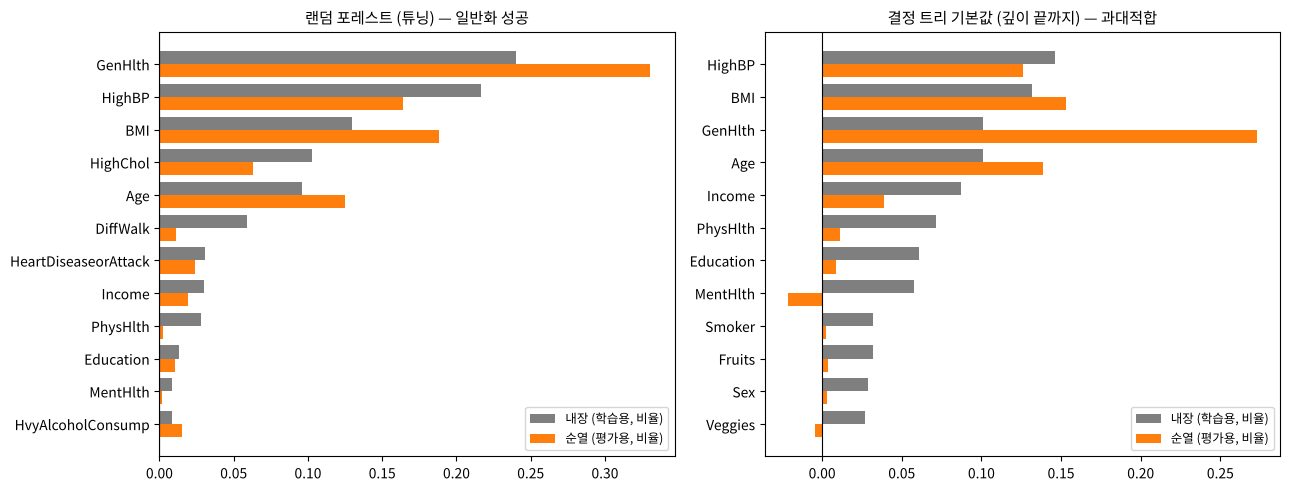

상위 5개 겹치는 수 — 랜덤 포레스트 : 5  / 기본값 트리 : 4
기본값 트리에서 순열 중요도가 0 이하인 특성 : ['Veggies', 'MentHlth']


In [11]:
# 같은 그림을 과대적합 모델(기본값 결정 트리, 끝까지 자람)과 비교
deep_dt = DecisionTreeClassifier(random_state=0).fit(X_train, y_train)
perm_deep = permutation_importance(deep_dt, X_test, y_test, scoring='accuracy', n_repeats=5, random_state=0, n_jobs=-1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (title, b, pm) in zip(axes, [('랜덤 포레스트 (튜닝) — 일반화 성공', best_rf.feature_importances_, perm.importances_mean),
                                     ('결정 트리 기본값 (깊이 끝까지) — 과대적합', deep_dt.feature_importances_, perm_deep.importances_mean)]):
    d = pd.DataFrame({'내장': b / b.sum(), '순열': pm / np.abs(pm).sum()}, index=feat).sort_values('내장').tail(12)
    y = np.arange(len(d))
    ax.barh(y + 0.2, d['내장'], height=0.4, color='tab:gray', label='내장 (학습용, 비율)')
    ax.barh(y - 0.2, d['순열'], height=0.4, color='tab:orange', label='순열 (평가용, 비율)')
    ax.set_yticks(y, d.index); ax.axvline(0, color='k', lw=0.8); ax.set_title(title, fontsize=11); ax.legend(fontsize=9, loc='lower right')
plt.tight_layout()
plt.savefig('./images/03_feature_importance.png', dpi=110, bbox_inches='tight')
plt.show()

def top_overlap(a, b, k=5):
    return len(set(pd.Series(a, index=feat).nlargest(k).index) & set(pd.Series(b, index=feat).nlargest(k).index))
print("상위 5개 겹치는 수 — 랜덤 포레스트 :", top_overlap(best_rf.feature_importances_, perm.importances_mean),
      " / 기본값 트리 :", top_overlap(deep_dt.feature_importances_, perm_deep.importances_mean))
print("기본값 트리에서 순열 중요도가 0 이하인 특성 :", list(feat[perm_deep.importances_mean <= 0]))

In [12]:
# 🎬 애니메이션 : 순열 중요도 — 특성 한 열을 섞을 때마다 정확도가 얼마나 떨어지나 (랜덤 포레스트)
base_acc = accuracy_score(y_test, best_rf.predict(X_test))
order = imp_perm.sort_values(ascending=False).index
drops = imp_perm.to_dict()          # 위 permutation_importance 결과 (5번 섞은 평균)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={'width_ratios': [1, 1.6]})
sample_rows = 12
def draw(i):
    for ax in axes: ax.clear()
    c = order[i]
    ax = axes[0]
    col0 = X_test[c].values[:sample_rows]; col1 = np.random.default_rng(i).permutation(X_test[c].values)[:sample_rows]
    ax.axis('off'); ax.set_title(f'"{c}" 열만 섞기', fontsize=11)
    for r in range(sample_rows):
        ax.text(0.15, 1 - (r + 1) / (sample_rows + 1), f'{col0[r]:g}', ha='center', fontsize=10)
        ax.text(0.5, 1 - (r + 1) / (sample_rows + 1), '→', ha='center', fontsize=10, color='gray')
        ax.text(0.85, 1 - (r + 1) / (sample_rows + 1), f'{col1[r]:g}', ha='center', fontsize=10, color='tab:orange')
    ax.text(0.15, 1, '원래', ha='center', fontsize=9); ax.text(0.85, 1, '섞은 뒤', ha='center', fontsize=9, color='tab:orange')
    ax = axes[1]
    names = list(order[:i + 1])[::-1]
    ax.barh(names, [drops[n] for n in names], color=['tab:orange' if n == c else 'tab:gray' for n in names])
    ax.set_xlim(min(0, min(drops.values())) - 0.002, max(drops.values()) * 1.15)
    ax.set_xlabel(f'정확도 하락 (원래 {base_acc:.4f})'); ax.set_title(f'{c} : 정확도 {-drops[c]:+.4f}', fontsize=11)
    fig.tight_layout()

ani = FuncAnimation(fig, draw, frames=list(range(len(order))) + [len(order) - 1] * 4, interval=400)
ani.save('./images/anim_05_permutation.gif', writer=PillowWriter(fps=3), dpi=72)
plt.close()
print("저장 : ./images/anim_05_permutation.gif")

저장 : ./images/anim_05_permutation.gif


![순열 중요도 애니메이션](./images/anim_05_permutation.gif)

🎬 평가용에서 특성 **한 열만** 섞으면 그 열과 정답의 관계가 끊긴다. 정확도가 많이 떨어질수록 모델이 **실제로 기대던** 특성. 뒤로 갈수록 섞어도 거의 안 떨어진다 = 없어도 되는 특성.

- 튜닝한 랜덤 포레스트 : 상위 5개(**GenHlth 건강 자가평가 · HighBP 고혈압 · BMI · HighChol · Age**)가 내장 · 순열에서 **5개 모두 겹친다** → 학습에서 배운 근거가 평가용에서도 통한다 = **일반화 성공**. (DiffWalk · PhysHlth 는 순열에서 낮은데, GenHlth 와 겹치는 정보라 한 열을 섞어도 다른 열이 메워 주기 때문 — 순열 중요도의 한계.)
- 기본값 결정 트리 : 상위권은 비슷하지만, 내장 중요도가 **Income · PhysHlth · Education · MentHlth · Smoker · Fruits · Sex · Veggies** 에도 꽤 나눠져 있는데 순열에서는 거의 **0**, **MentHlth · Veggies 는 음수**(섞었더니 오히려 더 맞힘) → 학습용의 잡음을 쪼개서 외운 흔적 = **과대적합**. (내장 중요도는 값 종류가 많은 특성을 부풀리는 경향도 있다.)

> **📝 고친 부분** (`분류 모델 성능 고도화 실습 1`)
> - 주석 "accuracy_score -> classification_report로 **변견**" → **변경**. "평가용 데이터 **대한** 성능" → 데이터**에** 대한.
> - `classification_report` 를 "4가지 성능" 이라고 했지만 실제로는 **정밀도 · 재현율 · F1 (클래스별) + 정확도 + support** 이고 macro · weighted 평균이 붙는다 (2절).
> - 기본 `digits=2` 라 튜닝 전후 · 모델끼리 차이가 0.75 vs 0.75 로 안 보임 → `digits=4`.